# Treinamento — classificação de peças com YOLO

Execute as células em ordem no **Google Colab**. Em **Ambiente de execução → Alterar tipo de ambiente de execução**, selecione uma **GPU**.

As imagens devem estar **já recortadas na ROI da aplicação**. O notebook não seleciona nem aplica essa ROI novamente. Cada pasta representa uma classe. Ao final, você terá o arquivo `best.pt` para usar na aplicação.

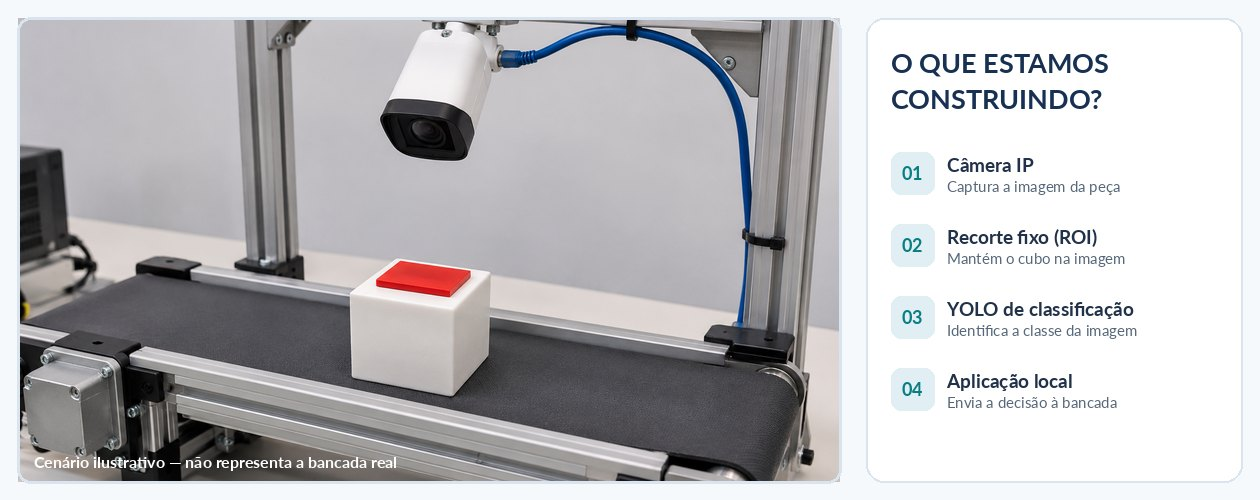

*Ilustração didática — exemplos de peças e classes; os nomes reais dependem da equipe.*

## 1. Instalar e configurar
O sufixo `-cls` identifica um modelo de classificação. Usaremos pesos já treinados como ponto de partida e os ajustaremos às classes da equipe.

In [ ]:
%pip install -q "ultralytics==8.4.204"

from pathlib import Path
import torch
import ultralytics
from ultralytics import YOLO

DATASET = Path("/content/dataset")  # Pasta com os recortes separados por classe
MODELO_INICIAL = "yolo11n-cls.pt"  # Pesos iniciais de classificação
EPOCAS = 30  # Quantidade de passagens pelo conjunto de treino
TAMANHO = 224  # Mesmo valor de TAMANHO_IMAGEM em inspecao.py
LOTE = 16  # Quantidade de imagens em cada lote

if not torch.cuda.is_available():
    raise RuntimeError("Selecione uma GPU no menu do Colab antes de continuar.")
print("GPU:", torch.cuda.get_device_name(0))
print("Ultralytics:", ultralytics.__version__)

## 2. Importar as imagens
Envie um ZIP contendo a pasta `dataset/` com esta estrutura. Use `boa` para peças aprovadas e `ruim` para peças reprovadas, conforme o mapeamento MQTT em `inspecao.py`:

```text
dataset/
├── train/
│   ├── boa/  (imagens de treino de peças aprovadas)
│   └── ruim/  (imagens de treino de peças reprovadas)
└── val/
    ├── boa/  (imagens de validação de peças aprovadas)
    └── ruim/  (imagens de validação de peças reprovadas)
```

Os nomes das pastas tornam-se os nomes das classes no `best.pt`. Você pode usar outros nomes, mas precisa ajustar as chaves de `COMANDOS` em `inspecao.py` para coincidir exatamente com eles.

Use capturas diferentes em treino e validação. Evite distribuir imagens quase idênticas entre os dois conjuntos.

Mantenha o mesmo enquadramento da aplicação, de preferência com **ROI quadrada**: o YOLO também faz recortes internos. `imgsz` define o tamanho da entrada do modelo, não as coordenadas da ROI.

Use as imagens já recortadas diretamente. Para importar outro dataset, reinicie o ambiente do Colab antes de extrair o novo ZIP.

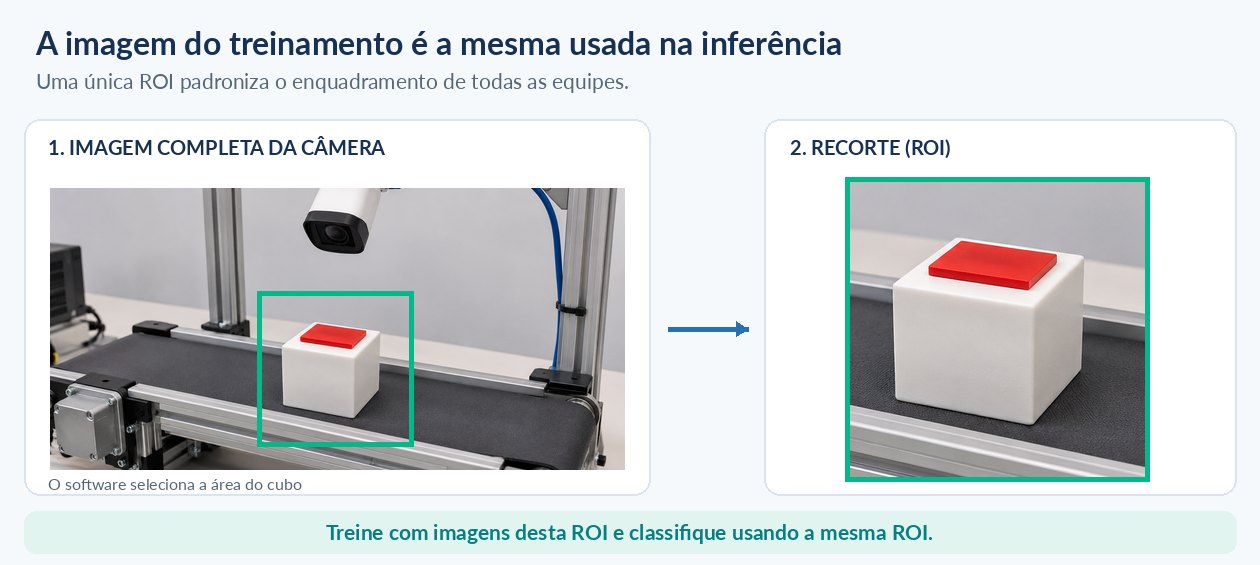

In [ ]:
from google.colab import files
from zipfile import ZipFile

enviados = files.upload()  # Selecione somente o ZIP do dataset
nome_zip = next(iter(enviados))
with ZipFile(nome_zip) as arquivo:
    arquivo.extractall("/content")

## 3. Conferir classes e imagens
`train` e `val` devem conter as mesmas classes, com imagens em todas as pastas. O exemplo exige pelo menos duas classes. Confira se a imagem exibida corresponde ao nome de sua pasta.

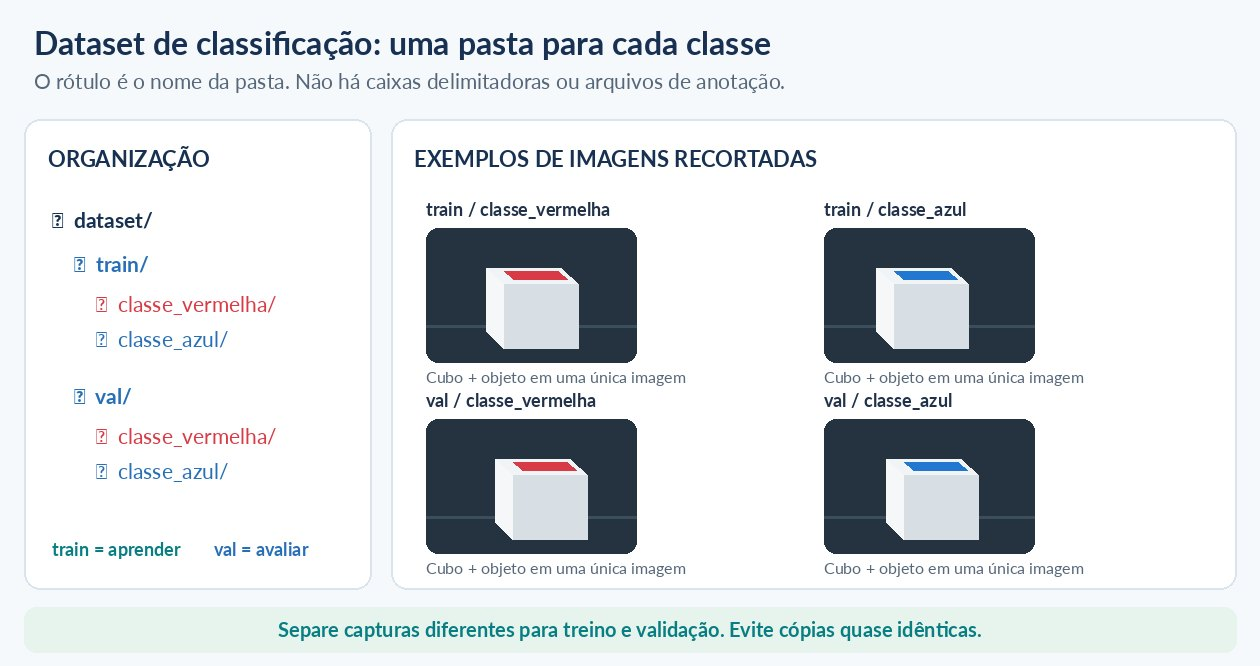

*Ilustração didática — exemplos de peças e classes; os nomes reais dependem da equipe.*

In [ ]:
from PIL import Image
from IPython.display import display

EXTENSOES = {".jpg", ".jpeg", ".png"}
classes = sorted(p.name for p in (DATASET / "train").iterdir() if p.is_dir())
classes_val = sorted(p.name for p in (DATASET / "val").iterdir() if p.is_dir())
if len(classes) < 2 or classes != classes_val:
    raise ValueError("Use pelo menos duas classes, com as mesmas pastas em train e val.")
for etapa in ["train", "val"]:
    for classe in classes:
        imagens = [p for p in (DATASET / etapa / classe).iterdir() if p.suffix.lower() in EXTENSOES]
        if not imagens:
            raise ValueError(f"Pasta sem imagens: {etapa}/{classe}")
        print(f"{etapa}/{classe}: {len(imagens)} imagens")
        if etapa == "train":
            display(Image.open(imagens[0]))

## 4. Treinar
`train()` ajusta os pesos com as imagens de `train` e verifica o desempenho em `val` ao longo do treinamento.

**Augmentation** cria variações das imagens durante o treino. Começaremos com os aumentos abaixo desativados para preservar cor, orientação e detalhes da peça. Os valores são explícitos porque o YOLO ativa alguns aumentos por padrão.

| Controle | Quando experimentar |
|---|---|
| `hsv_h`, `hsv_s`, `hsv_v` | Variações de cor e iluminação, se não mudarem a classe |
| `fliplr` | Espelhamento, se esquerda e direita não distinguirem as classes |
| `scale` | Variação do recorte interno, se não remover partes importantes |
| `erasing` | Apagamento de regiões, se não esconder o defeito procurado |
| `auto_augment` | Combinação automática de aumentos, depois de avaliar quais preservam as classes |

`0.0` desativa esses ajustes; `auto_augment` usa `None`. Isso mantém o pré-processamento interno, como redimensionamento e recorte. Teste um ajuste por vez e compare a validação. Mais épocas não substituem imagens variadas.

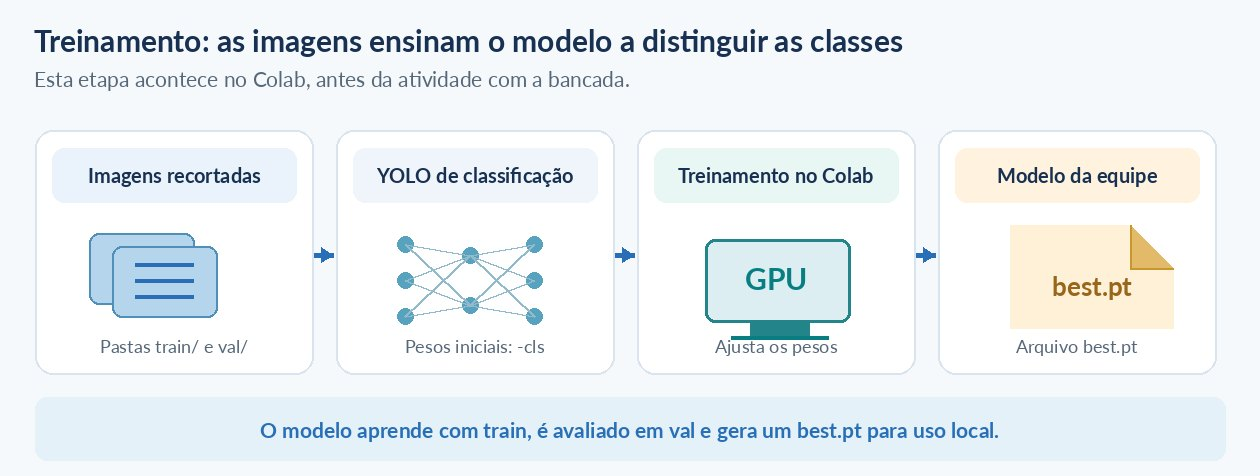

In [ ]:
modelo = YOLO(MODELO_INICIAL)  # Carrega os pesos iniciais, baixados no Colab
modelo.train(
    data=str(DATASET),  # Pasta com train e val, contendo as imagens já recortadas
    epochs=EPOCAS,  # Número de passagens pelo conjunto de treino
    imgsz=TAMANHO,  # Lado da entrada quadrada do modelo, em pixels
    batch=LOTE,  # Quantidade de imagens por lote
    device=0,  # GPU de índice 0 do Colab

    # Augmentation: comece preservando as características das peças
    auto_augment=None,  # Políticas automáticas de aumento
    hsv_h=0.0,  # Variação de matiz (tom da cor)
    hsv_s=0.0,  # Variação de saturação (intensidade da cor)
    hsv_v=0.0,  # Variação de brilho e contraste
    fliplr=0.0,  # Variação de espelhamento horizontal
    scale=0.0,  # Variação aleatória da área de recorte
    erasing=0.0,  # Apagamento aleatório de regiões
)
melhores_pesos = Path(modelo.trainer.best)  # Caminho do best.pt deste treinamento
print("Pesos salvos em:", melhores_pesos)

## 5. Avaliar o melhor modelo
`val()` calcula a **acurácia**: a proporção de imagens de validação classificadas corretamente. `predict()` mostra a classe prevista e a confiança para uma imagem já recortada.

A validação também é usada para escolher o `best.pt`. Por isso, faça o teste final com novas capturas na aplicação. **Confiança** é a pontuação do modelo para uma previsão; não é a acurácia do conjunto.

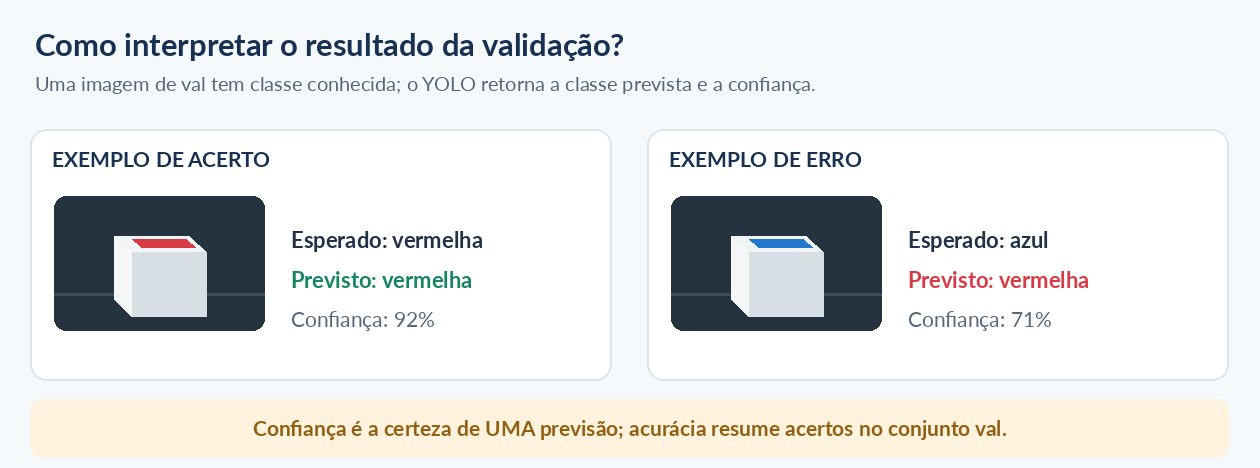

In [ ]:
modelo_treinado = YOLO(str(melhores_pesos))  # Carrega o melhor modelo salvo
metricas = modelo_treinado.val(
    data=str(DATASET),  # Pasta do dataset; a avaliação usa val
    imgsz=TAMANHO,  # Mesmo tamanho de entrada usado no treino
    device=0,  # Executa a validação na GPU do Colab
)
print(f"Acurácia de validação: {metricas.top1:.1%}")

# Mostra uma previsão por classe, para até quatro classes
for classe in classes[:4]:
    imagens = [p for p in (DATASET / "val" / classe).iterdir() if p.suffix.lower() in EXTENSOES]
    resultado = modelo_treinado.predict(
        source=str(imagens[0]),  # Uma imagem já recortada da validação
        imgsz=TAMANHO,  # Mesmo tamanho de entrada usado no treino
        verbose=False,  # Oculta as mensagens de execução de cada previsão
    )[0]  # Seleciona o resultado da única imagem enviada
    indice = resultado.probs.top1  # Índice da classe com maior pontuação
    display(Image.open(imagens[0]))
    print(
        f"Esperado: {classe} | Previsto: {resultado.names[indice]} | "
        f"Confiança: {float(resultado.probs.top1conf):.1%}"
    )

## 6. Levar o modelo para a aplicação
Execute a próxima célula para baixar `best.pt` e coloque-o na mesma pasta de `app.py`. Para conferir primeiro a classificação, ajuste `ENVIAR_NODE_RED = False`, reinicie o servidor Flask com `python app.py` e abra `http://localhost:5000`.

- **Classificar Agora** analisa a imagem atual sem exigir calibração do fundo
- **Calibrar Fundo**, com a região vazia, prepara a classificação automática por chegada da peça

Retire a peça antes do próximo ciclo. A classificação local não precisa de internet.

Depois de validar as previsões, confira `COMANDOS` em `inspecao.py`: `boa` usa `camera/boa` e `ruim` usa `camera/ruim`. Em cada comando, a aplicação publica `1`, espera 1 segundo e publica `0` no mesmo tópico para reiniciar o estado do PLC. Ajuste `ENVIAR_NODE_RED = True` e reinicie a aplicação para habilitar o envio MQTT. O computador precisa alcançar o broker pela rede local.

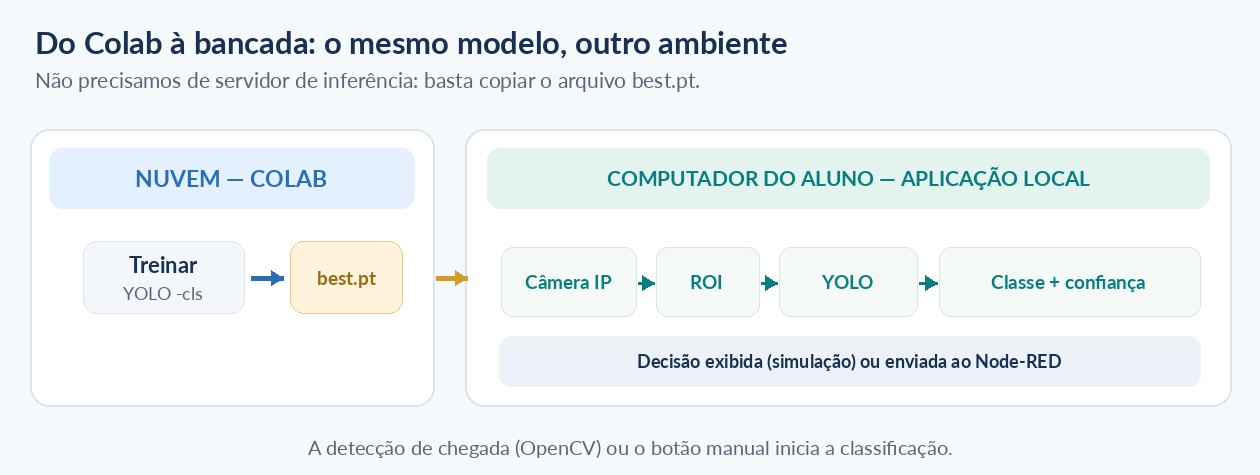

In [ ]:
files.download(str(melhores_pesos))

Referências: [classificação YOLO](https://docs.ultralytics.com/tasks/classify/), [estrutura do dataset](https://docs.ultralytics.com/datasets/classify/) e [parâmetros de treinamento](https://docs.ultralytics.com/modes/train/).